In [81]:
#Importing libraries

In [80]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [4]:
#Load row data

In [6]:
df = pd.read_csv('flipkart_com-ecommerce_sample.csv')

In [7]:
#Select Relevant columns for analysis

In [9]:
columns = [
    'uniq_id',
    'product_name',
    'product_category_tree',
    'retail_price',
    'discounted_price',
    'brand',
    'is_FK_Advantage_product'
]

df_subset = df[columns].copy()

In [10]:
# Inspect shape and missing counts

In [12]:
print("Rows & Columns:", df_subset.shape)
print("\nMissing values:\n", df_subset.isnull().sum())

Rows & Columns: (20000, 7)

Missing values:
 uniq_id                       0
product_name                  0
product_category_tree         0
retail_price                 78
discounted_price             78
brand                      5864
is_FK_Advantage_product       0
dtype: int64


In [13]:
# View first 5 rows

In [14]:
df_subset.head(5)

,uniq_id,product_name,product_category_tree,retail_price,discounted_price,brand,is_FK_Advantage_product
0,c2d766ca982eca8304150849735ffef9,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",999.0,379.0,Alisha,False
1,7f7036a6d550aaa89d34c77bd39a5e48,FabHomeDecor Fabric Double Sofa Bed,"[""Furniture >> Living Room Furniture >> Sofa B...",32157.0,22646.0,FabHomeDecor,False
2,f449ec65dcbc041b6ae5e6a32717d01b,AW Bellies,"[""Footwear >> Women's Footwear >> Ballerinas >...",999.0,499.0,AW,False
3,0973b37acd0c664e3de26e97e5571454,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",699.0,267.0,Alisha,False
4,bc940ea42ee6bef5ac7cea3fb5cfbee7,Sicons All Purpose Arnica Dog Shampoo,"[""Pet Supplies >> Grooming >> Skin & Coat Care...",220.0,210.0,Sicons,False


In [16]:
#Convert Prices to Numeric

In [19]:
df_subset['retail_price'] = pd.to_numeric(df_subset['retail_price'], errors='coerce')
df_subset['discounted_price'] = pd.to_numeric(df_subset['discounted_price'], errors='coerce')

In [20]:
# Drop rows where retail_price or discounted_price is missing

In [22]:
df_clean = df_subset.dropna(subset=['retail_price', 'discounted_price']).copy()

In [23]:
# Remove invalid records (e.g. retail price <= 0 or discounted price > retail price)

In [26]:
df_clean = df_clean[
    (df_clean['retail_price'] > 0) & 
    (df_clean['discounted_price'] >= 0) & 
    (df_clean['retail_price'] >= df_clean['discounted_price'])
]

In [27]:
# Calculate Discount Amount and Discount Percentage

In [28]:
df_clean['discount_amount'] = df_clean['retail_price'] - df_clean['discounted_price']
df_clean['discount_percentage'] = ((df_clean['discount_amount'] / df_clean['retail_price']) * 100).round(2)

In [29]:
# Check results

In [32]:
print("Cleaned Rows Count", len(df_clean))
df_clean[['retail_price', 'discounted_price', 'discount_amount', 'discount_percentage']].head(10)

Cleaned Rows Count 19922


,retail_price,discounted_price,discount_amount,discount_percentage
0,999.0,379.0,620.0,62.06
1,32157.0,22646.0,9511.0,29.58
2,999.0,499.0,500.0,50.05
3,699.0,267.0,432.0,61.80
4,220.0,210.0,10.0,4.55
5,430.0,430.0,0.0,0.00
6,1199.0,479.0,720.0,60.05
7,32157.0,22646.0,9511.0,29.58
8,699.0,349.0,350.0,50.07
9,1199.0,479.0,720.0,60.05


In [33]:
# Function to extract category by level

In [35]:
def extract_category(tree_value, level = 0):
    if pd.isna(tree_value):
        return 'Others'
    clean_text = str(tree_value).strip('[]"\'')
    parts = clean_text.split(' >> ')
    if len(parts) > level:
        return parts[level].strip()
    return 'Others'

In [36]:
# Apply function to create new columns

In [37]:
df_clean['primary_category'] = df_clean['product_category_tree'].apply(lambda x: extract_category(x, 0))
df_clean['sub_category'] = df_clean['product_category_tree'].apply(lambda x: extract_category(x, 1))

In [41]:
# Check top 10 categories

In [40]:
print(df_clean['primary_category'].value_counts().head(10))

primary_category
Clothing                      6171
Jewellery                     3522
Footwear                      1225
Mobiles & Accessories         1097
Automotive                    1010
Home Decor & Festive Needs     927
Beauty and Personal Care       709
Home Furnishing                700
Kitchen & Dining               645
Computers                      573
Name: count, dtype: int64


In [42]:
# Handle missing brands

In [43]:
df_clean['brand'] = df_clean['brand'].fillna('Generic / Unknown')

In [44]:
# Define price segment bins and labels

In [45]:
bins = [0, 500, 1000, 2500, 5000, float('inf')]
labels = ['Budget (<500)', 'Affordable (<500-1k)', 'Mid-Range(1k-2.5k)', 'Upper-Mid (2.5k-5k)', 'Premire / luxury (>5k)']

In [46]:
# Create price_segment column using pd.cut

In [47]:
df_clean['price_segment'] = pd.cut(df_clean['discounted_price'], bins=bins, labels=labels)

In [48]:
# Check distribution of price segments

In [49]:
print(df_clean['price_segment'].value_counts())

price_segment
Budget (<500)             9444
Affordable (<500-1k)      5568
Mid-Range(1k-2.5k)        3343
Premire / luxury (>5k)    1064
Upper-Mid (2.5k-5k)        503
Name: count, dtype: int64


In [50]:
# 1. Select final columns

In [58]:
final_columns = [
    'uniq_id',
    'product_name',
    'brand',
    'primary_category',
    'sub_category',
    'retail_price',
    'discounted_price',
    'discount_amount',
    'discount_percentage',
    'price_segment',
    'is_FK_Advantage_product'
]

In [52]:
# 2. Create final dataframe and save to CSV

In [59]:
df_final = df_clean[final_columns].copy()
df_final.to_csv('flipkart_cleaned.csv', index=False)

In [60]:
# 3. Verify output

In [64]:
print("File Saved Successfully as 'flipkart_cleaned.csv'")
print("Total rows:", len(df_final))
df_final.head(5)

File Saved Successfully as 'flipkart_cleaned.csv'
Total rows: 19922


,uniq_id,product_name,brand,primary_category,sub_category,retail_price,discounted_price,discount_amount,discount_percentage,price_segment,is_FK_Advantage_product
0,c2d766ca982eca8304150849735ffef9,Alisha Solid Women's Cycling Shorts,Alisha,Clothing,Women's Clothing,999.0,379.0,620.0,62.06,Budget (<500),False
1,7f7036a6d550aaa89d34c77bd39a5e48,FabHomeDecor Fabric Double Sofa Bed,FabHomeDecor,Furniture,Living Room Furniture,32157.0,22646.0,9511.0,29.58,Premire / luxury (>5k),False
2,f449ec65dcbc041b6ae5e6a32717d01b,AW Bellies,AW,Footwear,Women's Footwear,999.0,499.0,500.0,50.05,Budget (<500),False
3,0973b37acd0c664e3de26e97e5571454,Alisha Solid Women's Cycling Shorts,Alisha,Clothing,Women's Clothing,699.0,267.0,432.0,61.80,Budget (<500),False
4,bc940ea42ee6bef5ac7cea3fb5cfbee7,Sicons All Purpose Arnica Dog Shampoo,Sicons,Pet Supplies,Grooming,220.0,210.0,10.0,4.55,Budget (<500),False


In [65]:
# 1. Price metrics calculate karne

In [70]:
# 1. Price metrics calculate karne
print("--- FLIPKART PRICING SUMMARY ---")
print(f"Total Products Analyzed: {len(df_final):,}")
print(f"Retail Price (MRP) Mean: Rs. {df_final['retail_price'].mean():.2f}")
print(f"Retail Price (MRP) Median: Rs. {df_final['retail_price'].median():.2f}")
print(f"Discounted Price Mean: Rs. {df_final['discounted_price'].mean():.2f}")
print(f"Discounted Price Median: Rs. {df_final['discounted_price'].median():.2f}")
print(f"Average Discount %: {df_final['discount_percentage'].mean():.2f}%")
print(f"Median Discount %: {df_final['discount_percentage'].median():.2f}%")

# 2. Detailed numerical statistics
df_final[['retail_price', 'discounted_price', 'discount_amount', 'discount_percentage']].describe().round(2)

--- FLIPKART PRICING SUMMARY ---
Total Products Analyzed: 19,922
Retail Price (MRP) Mean: Rs. 2979.21
Retail Price (MRP) Median: Rs. 1040.00
Discounted Price Mean: Rs. 1973.40
Discounted Price Median: Rs. 550.00
Average Discount %: 40.52%
Median Discount %: 45.00%


,retail_price,discounted_price,discount_amount,discount_percentage
count,19922.00,19922.00,19922.00,19922.00
mean,2979.21,1973.40,1005.80,40.52
std,9009.64,7333.59,2301.34,23.55
min,35.00,35.00,0.00,0.00
25%,666.00,350.00,180.00,21.06
50%,1040.00,550.00,456.00,45.00
75%,1999.00,999.00,900.00,59.97
max,571230.00,571230.00,87675.00,96.53


In [71]:
# 1. Identify top 10 categories by product count

In [73]:
top_categories = df_final['primary_category'].value_counts().head().index

In [74]:
# 2. Group by category and compute summary metrics

In [78]:
cat_summary = df_final[df_final['primary_category'].isin(top_categories)].groupby('primary_category').agg(
    total_products=('retail_price', 'count'),
    mean_retail=('retail_price', 'mean'),
    median_retail=('retail_price', 'median'),
    mean_discounted=('discounted_price', 'mean'),
    median_discounted=('discounted_price', 'median'),
    avg_discount_pct=('discount_percentage', 'mean')
).sort_values(by='total_products', ascending=False).round(2)

In [76]:
# 3. Display summary table

In [79]:
cat_summary

,total_products,mean_retail,median_retail,mean_discounted,median_discounted,avg_discount_pct
primary_category,,,,,,
Clothing,6171,1369.22,999.0,714.36,499.0,45.07
Jewellery,3522,7662.52,999.0,5558.82,449.0,40.89
Footwear,1225,1744.17,1599.0,1077.31,899.0,36.27
Mobiles & Accessories,1097,1810.09,1999.0,957.37,599.0,50.99
Automotive,1010,2903.33,2800.0,1189.15,1350.0,54.65


In [89]:
#importing libraries

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

In [92]:
# Set figure size and grid layout (2 rows, 2 columns)

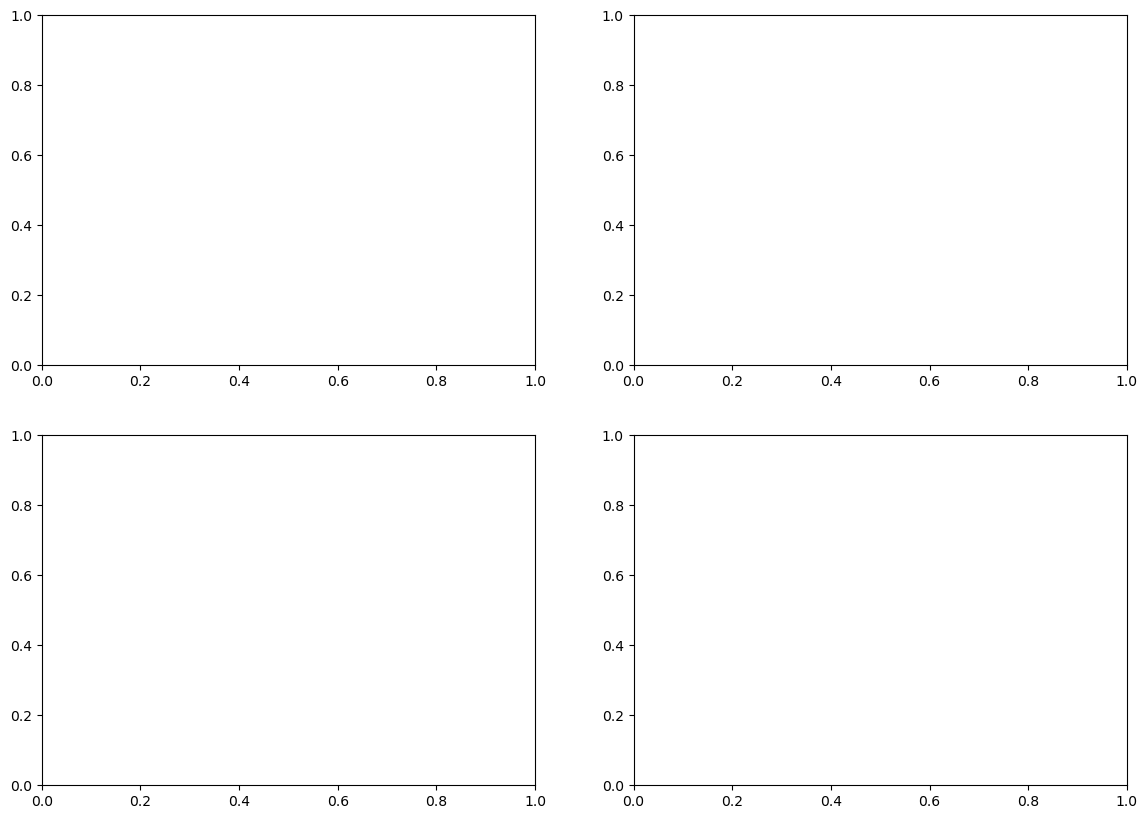

In [94]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

In [95]:
#Price Segment Distribution

In [98]:
segment_counts = df_final['price_segment'].value_counts()
axes[0, 0].bar(segment_counts.index.astype(str), segment_counts.values, color='#1f77b4', edgecolor='black')
axes[0, 0].set_title('Product Count by Price Segment')
axes[0, 0].set_ylabel('Number of Products')
axes[0, 0].tick_params(axis='x', rotation=30)

In [99]:
#Discount Percentage Distribution

In [101]:
sns.histplot(df_final['discount_percentage'], bins=20, kde=True, color='#9467bd', ax=axes[0, 1], edgecolor='black')
axes[0, 1].set_title('Distribution of Discount Percentages')
axes[0, 1].set_xlabel('Discount (%)')
axes[0, 1].set_ylabel('Count')

Text(596.2626262626262, 0.5, 'Count')

In [102]:
#Top 10 Product Categories

In [105]:
top_10 = df_final['primary_category'].value_counts().head(10)
axes[1, 0].barh(top_10.index[::-1], top_10.values[::-1], color='#2ca02c', edgecolor='black')
axes[1, 0].set_title('Top 10 Product Categories')
axes[1, 0].set_xlabel('Total Products')

Text(0.5, 4.4444444444444375, 'Total Products')

In [106]:
#Average Discount % by Top 10 Categories

In [110]:
cat_discount = df_final[df_final['primary_category'].isin(top_10.index)].groupby('primary_category')['discount_percentage'].mean().loc[top_10.index]
axes[1, 1].barh(cat_discount.index[::-1], cat_discount.values[::-1], color='#ff7f0e', edgecolor='black')
axes[1, 1].set_title('Avg Discount % by Top 10 Categories')
axes[1, 1].set_xlabel('Average Discount (%)')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>